# 22 — CNN (1D Convolutional Neural Network)

**Architecture:** Embedding → Conv1D(128, k=5, relu) → GlobalMaxPool → Dense(64, relu) → Dropout(0.3) → Dense(1, sigmoid)  
**Features:** Token sequences (max 200 tokens, vocab 30K)  
1D CNNs apply learnable filters over the token sequence to detect local n-gram patterns. GlobalMaxPooling selects the most active feature across all positions.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, plot_confusion_matrix, plot_roc_curve, plot_pr_curve)
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report)
BASE_DIR, FIGURES_DIR = setup_paths()
import tensorflow as tf
print(f'TensorFlow {tf.__version__}')

TensorFlow 2.21.0


In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)

MAX_WORDS, MAX_LEN, MAX_SAMPLES = 30000, 200, 80000
if len(X_train) > MAX_SAMPLES:
    np.random.seed(42)
    idx = np.random.choice(len(X_train), MAX_SAMPLES, replace=False)
    X_tr_raw, y_tr = X_train[idx], y_train[idx]
else:
    X_tr_raw, y_tr = X_train, y_train

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_tr_raw)
X_tr = pad_sequences(tokenizer.texts_to_sequences(X_tr_raw), maxlen=MAX_LEN, padding='post', truncating='post')
X_te = pad_sequences(tokenizer.texts_to_sequences(X_test),   maxlen=MAX_LEN, padding='post', truncating='post')
vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)
print(f'Vocabulary: {vocab_size:,}  |  Train: {len(X_tr):,}  |  Test: {len(X_te):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Vocabulary: 30,000  |  Train: 80,000  |  Test: 20,905


## Model Architecture

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

MODEL_NAME = 'CNN'
model = Sequential([
    Embedding(vocab_size, 128, input_length=MAX_LEN),
    Conv1D(128, kernel_size=5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
], name='CNN')
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
t0 = time.time()
history = model.fit(X_tr, y_tr, epochs=10, batch_size=64,
                    validation_split=0.1, callbacks=[early_stop], verbose=1)
train_time = time.time() - t0
print(f'\nTraining completed in {train_time:.1f}s')

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.7998 - loss: 0.3922 - val_accuracy: 0.8286 - val_loss: 0.3335
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 28s 25ms/step - accuracy: 0.8770 - loss: 0.2644 - val_accuracy: 0.8289 - val_loss: 0.3338
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 28s 25ms/step - accuracy: 0.9481 - loss: 0.1306 - val_accuracy: 0.8151 - val_loss: 0.4424
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 28s 25ms/step - accuracy: 0.9844 - loss: 0.0471 - val_accuracy: 0.8217 - val_loss: 0.5896
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.

Training completed in 114.3s


## Training Convergence

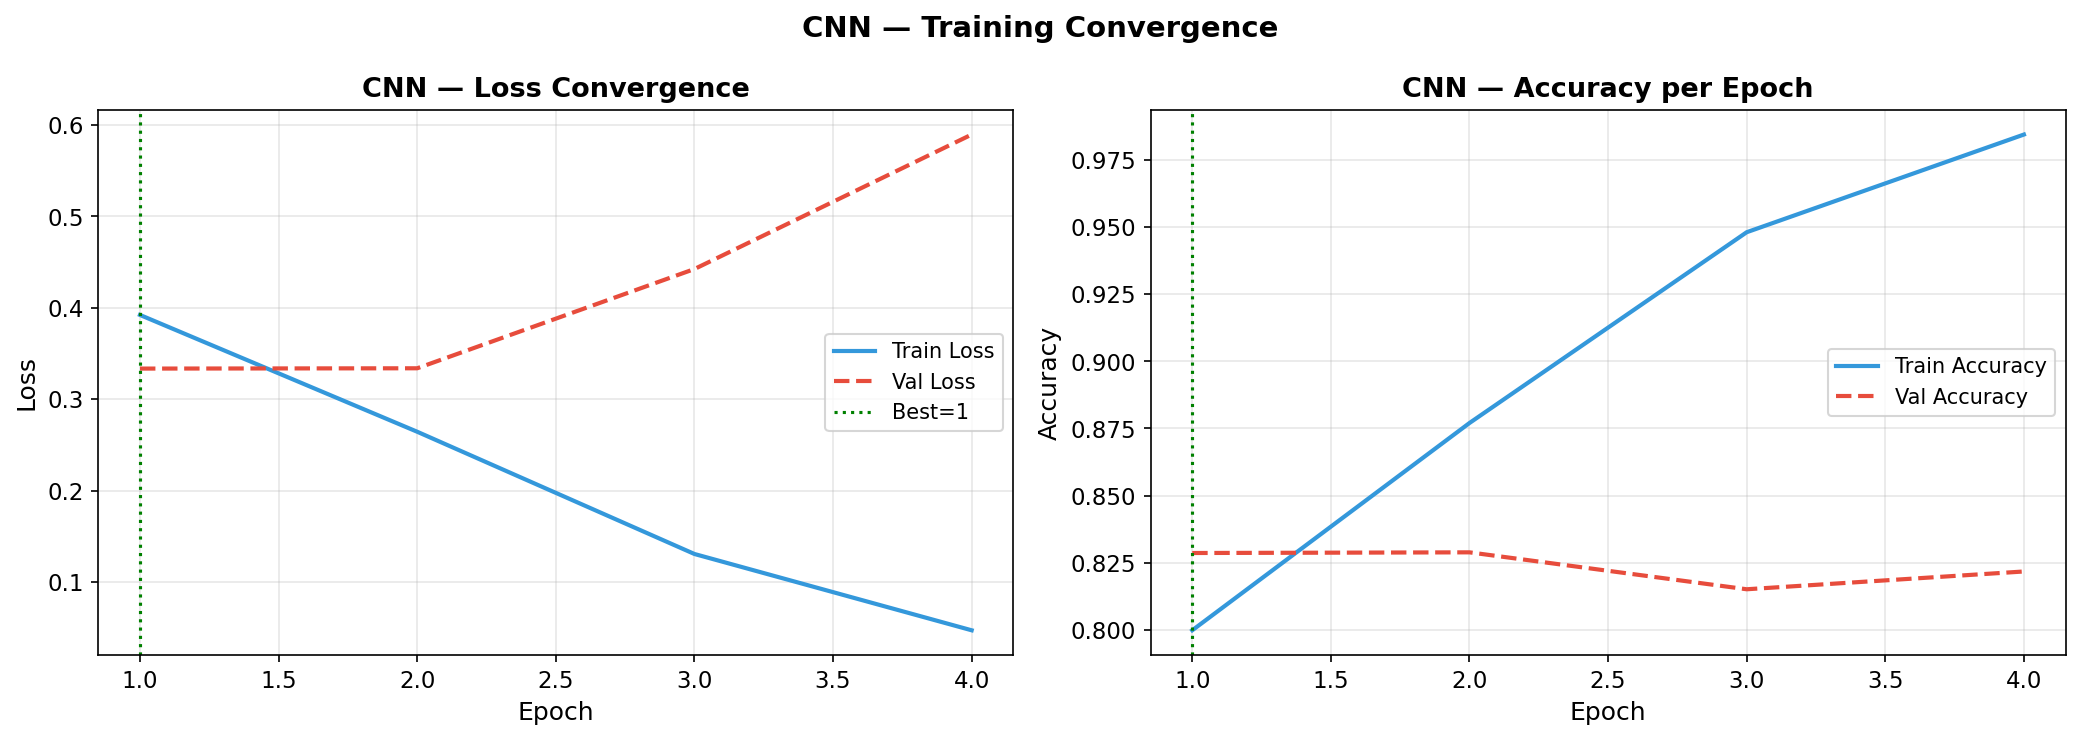

In [5]:
hist = history.history
epochs_run = range(1, len(hist['loss']) + 1)
best_ep = np.argmin(hist['val_loss']) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(epochs_run, hist['loss'],     '#3498db', lw=2, label='Train Loss')
axes[0].plot(epochs_run, hist['val_loss'], '#e74c3c', lw=2, linestyle='--', label='Val Loss')
axes[0].axvline(best_ep, color='green', linestyle=':', lw=1.5, label=f'Best={best_ep}')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].set_title('CNN — Loss Convergence')
axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_run, hist['accuracy'],     '#3498db', lw=2, label='Train Accuracy')
axes[1].plot(epochs_run, hist['val_accuracy'], '#e74c3c', lw=2, linestyle='--', label='Val Accuracy')
axes[1].axvline(best_ep, color='green', linestyle=':', lw=1.5)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].set_title('CNN — Accuracy per Epoch')
axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.suptitle('CNN — Training Convergence', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'cnn_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

In [6]:
y_prob = model.predict(X_te, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)
print(f'Accuracy : {accuracy_score(y_test, y_pred):.4f}')
print(f'F1 Score : {f1_score(y_test, y_pred, average="weighted"):.4f}')
print(f'AUC-ROC  : {roc_auc_score(y_test, y_prob):.4f}')
print(f'Train Time: {train_time:.1f}s')
print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

Accuracy : 0.8302
F1 Score : 0.8296
AUC-ROC  : 0.9230
Train Time: 114.3s
              precision    recall  f1-score   support

        Fake       0.81      0.77      0.79      8532
        Real       0.85      0.87      0.86     12373

    accuracy                           0.83     20905
   macro avg       0.83      0.82      0.82     20905
weighted avg       0.83      0.83      0.83     20905



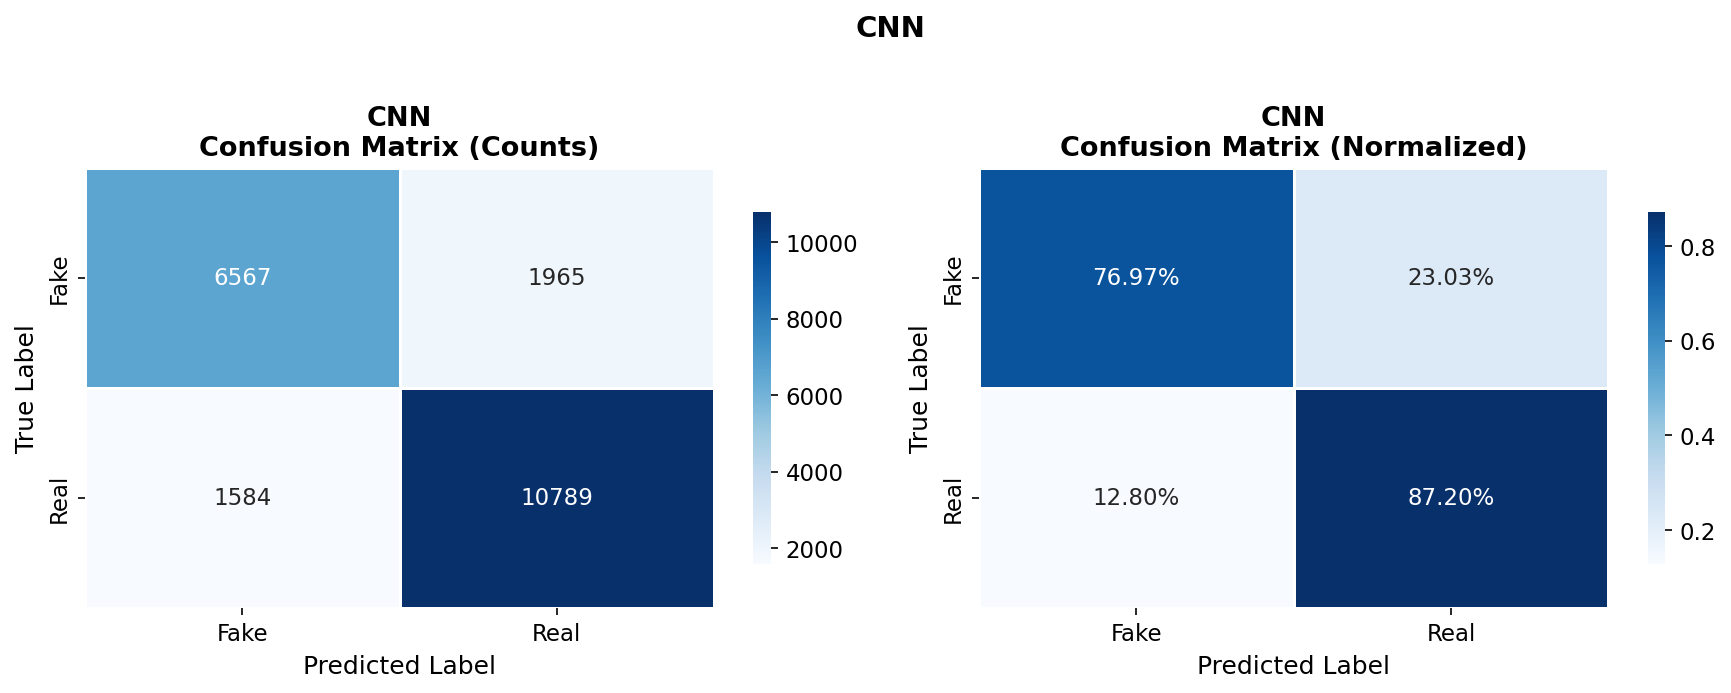

In [7]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

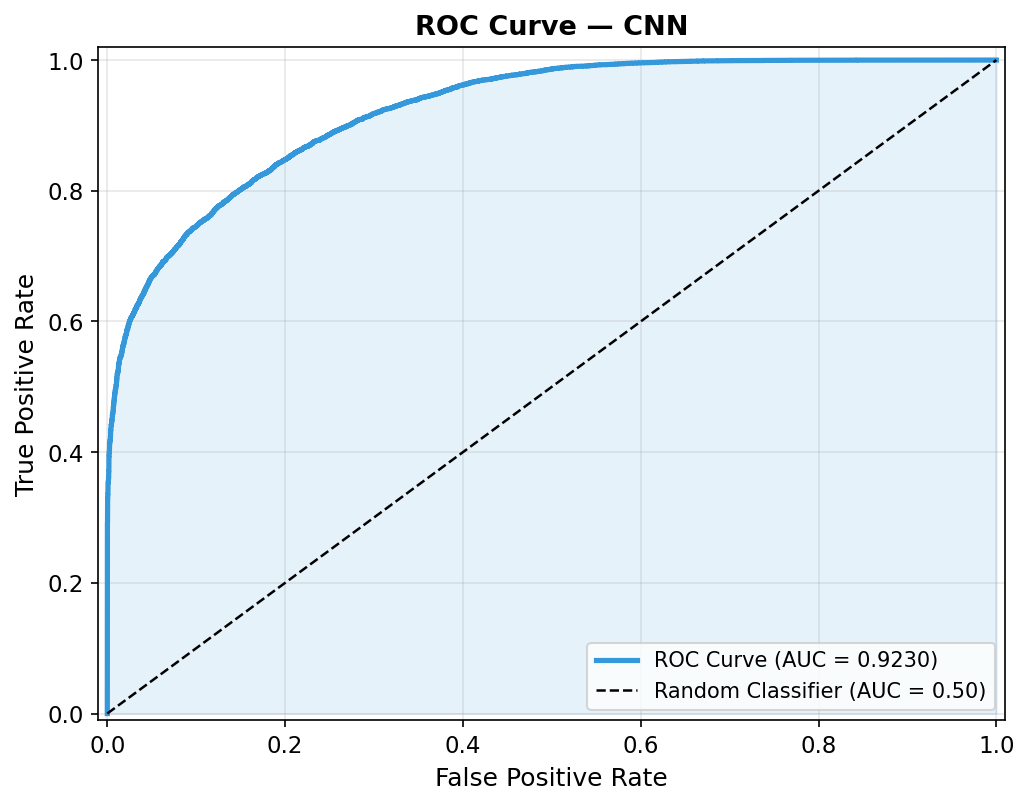

In [8]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

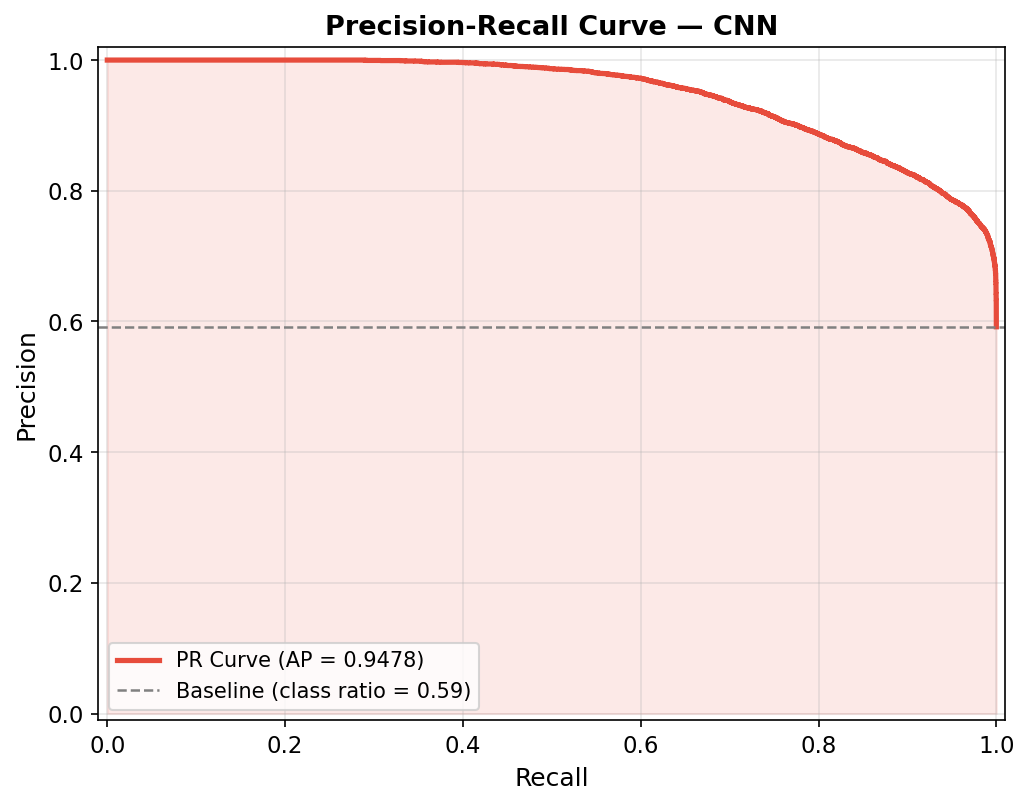

In [9]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Filter Size Comparison

  kernel_size=3: 0.8310
  kernel_size=5: 0.8285
  kernel_size=7: 0.8263
  kernel_size=9: 0.8273


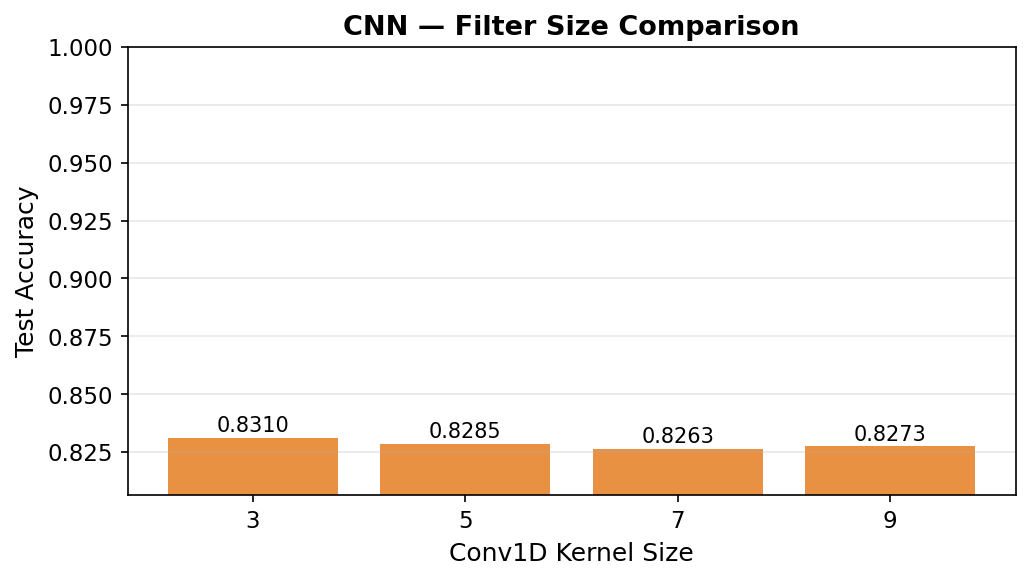

In [10]:
kernel_sizes = [3, 5, 7, 9]
kern_accs = []
for k in kernel_sizes:
    m = Sequential([
        Embedding(vocab_size, 128, input_length=MAX_LEN),
        Conv1D(128, kernel_size=k, activation='relu'),
        GlobalMaxPooling1D(),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    es = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
    m.fit(X_tr, y_tr, epochs=5, batch_size=64, validation_split=0.1,
          callbacks=[es], verbose=0)
    y_p = (m.predict(X_te, verbose=0).flatten() >= 0.5).astype(int)
    acc = accuracy_score(y_test, y_p)
    kern_accs.append(acc)
    print(f'  kernel_size={k}: {acc:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(k) for k in kernel_sizes], kern_accs, color='#e67e22', alpha=0.85)
for i, v in enumerate(kern_accs):
    ax.text(i, v + 0.001, f'{v:.4f}', ha='center', va='bottom', fontsize=10)
ax.set_xlabel('Conv1D Kernel Size')
ax.set_ylabel('Test Accuracy')
ax.set_title('CNN — Filter Size Comparison')
ax.set_ylim(min(kern_accs) - 0.02, 1.0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'cnn_kernel_size_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

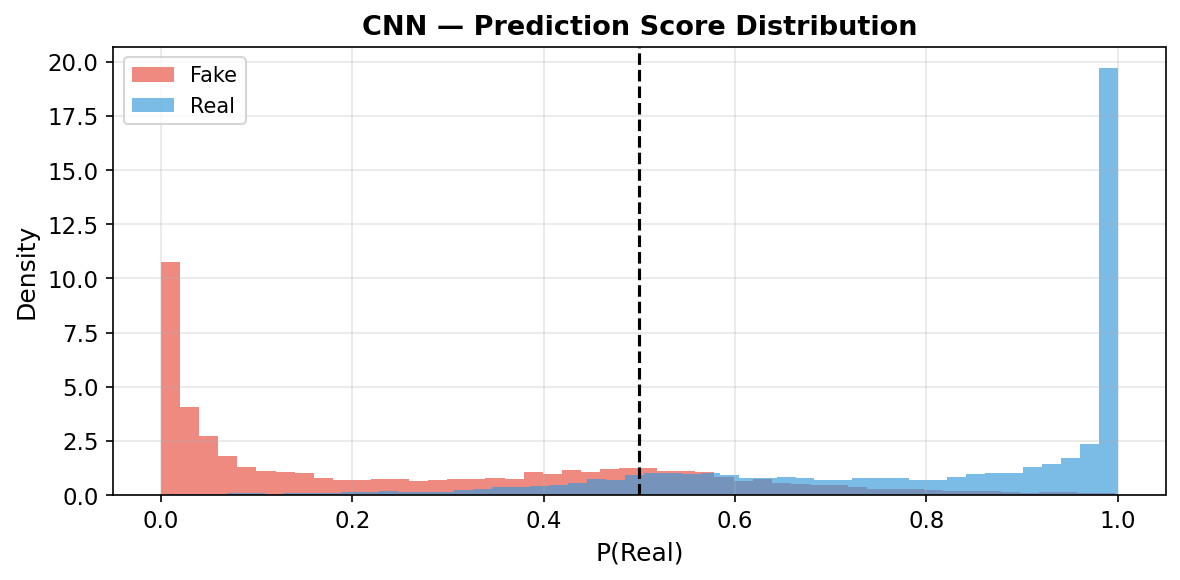

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_prob[y_test==0], bins=50, alpha=0.65, color='#e74c3c', label='Fake', density=True)
ax.hist(y_prob[y_test==1], bins=50, alpha=0.65, color='#3498db', label='Real', density=True)
ax.axvline(0.5, color='black', linestyle='--', lw=1.5)
ax.set_xlabel('P(Real)'); ax.set_ylabel('Density')
ax.set_title('CNN — Prediction Score Distribution')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'cnn_score_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()